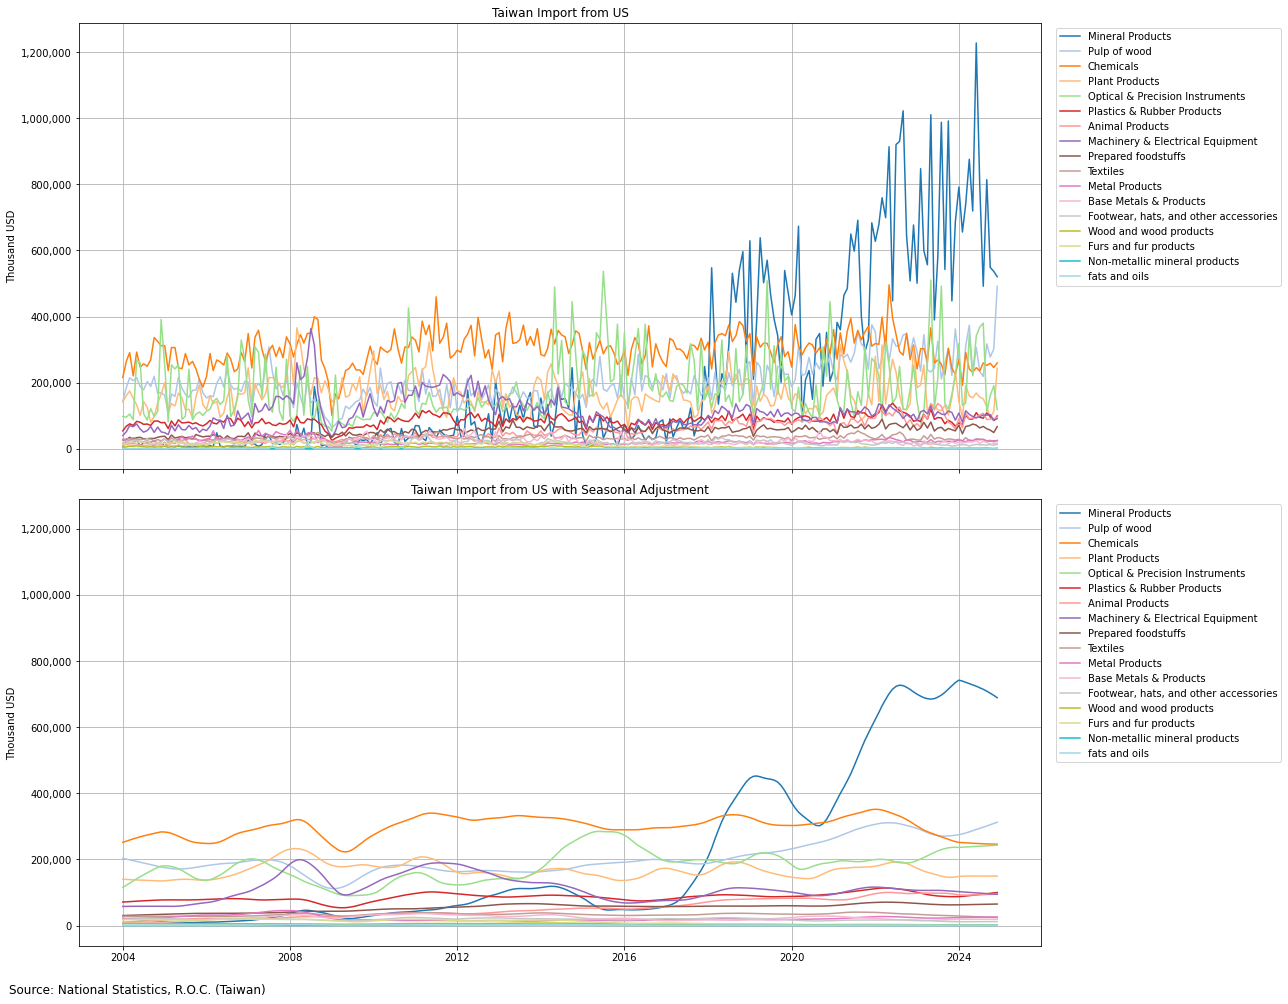

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from statsmodels.tsa.seasonal import STL
from matplotlib.ticker import FuncFormatter

file_path = "US Import.xlsx"
df = pd.read_excel(file_path)
df.rename(columns={df.columns[0]: "Date"}, inplace=True)
df["Year"] = df["Date"].str.extract(r'(\d+)年')[0].astype(int) + 1911
df["Month"] = df["Date"].str.extract(r'(\d+)月')[0].astype(int)
df["Date"] = pd.to_datetime(df[["Year", "Month"]].assign(day=1))
df.drop(columns=["Year", "Month"], inplace=True)

US_import = ["Animal Products", "Plant Products", "fats and oils", "Prepared foodstuffs",
    "Mineral Products", "Chemicals", "Plastics & Rubber Products", "Furs and fur products",
    "Wood and wood products", "Pulp of wood", "Textiles",
    "Footwear, hats, and other accessories", "Non-metallic mineral products",
    "Metal Products", "Base Metals & Products", "Machinery & Electrical Equipment",
    "Optical & Precision Instruments"]

latest_values = df[df["Date"].dt.year == 2024].iloc[-1][US_import]
sorted_cols = latest_values.sort_values(ascending=False).index.tolist()

colors = cm.get_cmap('tab20', len(sorted_cols))
fig, axes = plt.subplots(2, 1, figsize=(18, 14), sharex=True, sharey=True)

for i, col in enumerate(sorted_cols):
    axes[0].plot(df["Date"], df[col], label=col, color=colors(i))
axes[0].set_title("Taiwan Import from US")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[0].grid(True)
axes[0].set_ylabel("Thousand USD")

for i, col in enumerate(sorted_cols):
    ts = pd.Series(df[col].values, index=df["Date"]).asfreq("MS")
    try:
        trend = STL(ts, period=12).fit().trend
        axes[1].plot(trend, label=col, color=colors(i))
    except Exception as e:
        print(f"跳過：{col}，原因：{e}")
axes[1].set_title("Taiwan Import from US with Seasonal Adjustment")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[1].grid(True)
axes[1].set_ylabel("Thousand USD")

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")
for ax in axes:
    ax.yaxis.set_major_formatter(formatter)
plt.figtext(0.01, 0.01, "Source: National Statistics, R.O.C. (Taiwan)", ha='left', fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()